# <font color = "red">**Day 24: Physics-Informed Learning from Atomic-Resolution Microscopy**</font>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kbarakati/athena_camm_hackathon/blob/k4my4r/docs/day_24_11062026/reward_driven_image_analysis.ipynb)

**Challenge Overview**

Atomic-resolution scanning transmission electron microscopy (STEM) provides detailed information about the local structure of crystalline materials. However, extracting physically meaningful properties from microscopy images often requires specialized analysis, atomic-scale measurements, and knowledge of the underlying material structure.

**<font color = "blue">The goal of this challenge is to develop physics-informed algorithms that extract local material properties directly from high-angle annular dark-field (HAADF-STEM) images.</font>**

Participants will work with atomic-resolution images of Sm-doped BiFeO₃ (Sm-BFO) at different compositions (0%, 7%, 10%, 13%, and 20% Sm). 

- The primary objective is to reconstruct spatial maps of local polarization-related atomic displacements using image analysis, machine learning, or physics-guided computational methods.

**Participants may use:**

1. HAADF images: Raw atomic-resolution microscopy images.

2. Atomic coordinates (xy_atms): Positions of detected atomic columns.

3. Unit-cell coordinates (xy_COM): Reference positions associated with individual unit cells.

4. Structural parameters: Lattice parameters, unit-cell geometry, and other non-target structural descriptors.

5. Material information: Sm composition and relevant crystallographic knowledge.

Participants may combine these inputs with physical models, computer vision, statistical methods, or machine learning to reconstruct local material properties.

<font color = "red">**Ground Truth and Restrictions**</font>

Reference polarization-related displacement maps **(Pxy)** are provided for verification and evaluation only.

- Participants must not use these reference values as inputs to their algorithms, for model training, or for selecting and optimizing model parameters.

- The reference data may only be used after generating predictions to evaluate the agreement between reconstructed and reference maps.

- Any additional property used as an input must not directly encode or reproduce the reference polarization values.

### load data

In [10]:
import os
import h5py
import numpy as np
import matplotlib.pyplot as plt

In [2]:
! #gdown --folder "https://drive.google.com/drive/folders/1fXwChjwMT9PH5YtonZoDG3kXVL6mfEQg?usp=sharing"

In [11]:
#list files
filedir = 'data_small'
[f for f in os.listdir(filedir)]

['Copy of Sm_0_1_UCParameterization.h5',
 'Copy of Sm_10_1_UCParameterization.h5',
 'Copy of Sm_13_1_HAADF.h5',
 'Copy of Sm_0_1_HAADF.h5',
 'Copy of Sm_13_1_UCParameterization.h5',
 'Copy of Sm_7_3_UCParameterization.h5',
 'Copy of Sm_20_1_UCParameterization.h5',
 'Copy of Sm_20_1_HAADF.h5',
 'Copy of Sm_10_1_HAADF.h5',
 'Copy of Sm_7_3_HAADF.h5']

In [12]:
# Find HAADF images
img_filename = sorted(
    f for f in os.listdir(filedir) if f.endswith("_HAADF.h5")
)

# Match parameterization files
UCparam_filename = [
    f.replace("_HAADF.h5", "_UCParameterization.h5")
    for f in img_filename
]

# Extract Sm composition (%)
composition_tags = [
    int(f.replace("Copy of ", "").split("_")[1])
    for f in img_filename
]

# Load datasets
imgdata = [
    np.asarray(h5py.File(os.path.join(filedir, f), "r")["MainImage"])
    for f in img_filename
]

UCparam = [
    h5py.File(os.path.join(filedir, f), "r")
    for f in UCparam_filename
]

imnum = len(imgdata)

print(f"Loaded {imnum} images and parameterization files")
print("Sm compositions (%):", composition_tags)
print("UC parameters:", list(UCparam[0].keys()))


Loaded 5 images and parameterization files
Sm compositions (%): [0, 10, 13, 20, 7]
UC parameters: ['I1', 'I2', 'I3', 'I4', 'I5', 'NCOM', 'PCOM', 'Pxy', 'Vol', 'a', 'ab', 'abdelta', 'alpha', 'atmindex', 'b', 'index', 'meanuca', 'meanucb', 'nbrUC', 'xy_COM', 'xy_atms']


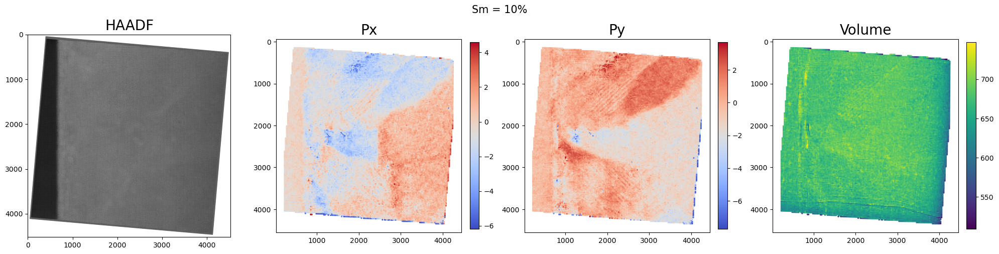

In [ ]:
idx = 1

# Load data
img = np.asarray(imgdata[idx]).squeeze()
pxy = np.asarray(UCparam[idx]["Pxy"]).T
vol = np.asarray(UCparam[idx]["Vol"]).ravel()
xy = np.asarray(UCparam[idx]["xy_COM"]).T


# Extract polarization components
px, py = pxy[:, 0], pxy[:, 1]

# Plot HAADF and unit-cell parameters
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("HAADF", fontsize =20)

for ax, data, title, cmap in zip(
    axes[1:],
    [px, py, vol],
    ["Px", "Py", "Volume"],
    ["coolwarm", "coolwarm", "viridis"]
):
    im = ax.scatter(
        xy[:, 1], xy[:, 0],
        c=data, cmap=cmap, s=5, marker="o", linewidths=0
    )
    ax.invert_yaxis()
    ax.set_title(title, fontsize =20)
    ax.set_aspect("equal")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# for ax in axes:
#     ax.axis("off")

fig.suptitle(f"Sm = {composition_tags[idx]}%", fontsize=15)
plt.tight_layout()
plt.show()


<font color = "red">**Look Closer**</font>

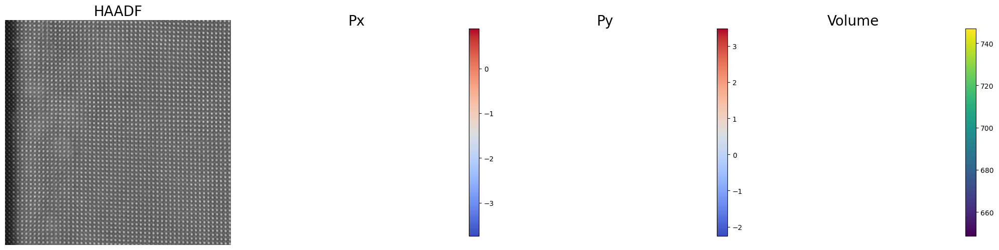

In [39]:
# Select region (image pixel coordinates)
xlim = (600, 2000)
ylim = (2000, 3400)

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

axes[0].imshow(img, cmap="gray")
axes[0].set_title("HAADF", fontsize = 20)

for ax, data, title, cmap in zip(
    axes[1:],
    [px, py, vol],
    ["Px", "Py", "Volume"],
    ["coolwarm", "coolwarm", "viridis"]
):
    im = ax.scatter(
        xy[:, 1], xy[:, 0],
        c=data, cmap=cmap, s=30, marker="o", linewidths=0
    )
    ax.set_title(title, fontsize = 20)
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

for ax in axes:
    ax.set_xlim(*xlim)
    ax.set_ylim(ylim[1], ylim[0])
    ax.set_aspect("equal")
    ax.axis("off")

plt.tight_layout()
plt.show()


<font color = "red">**atom cordinates and center of the mass**</font>

Original shape: (2, 5, 22949)


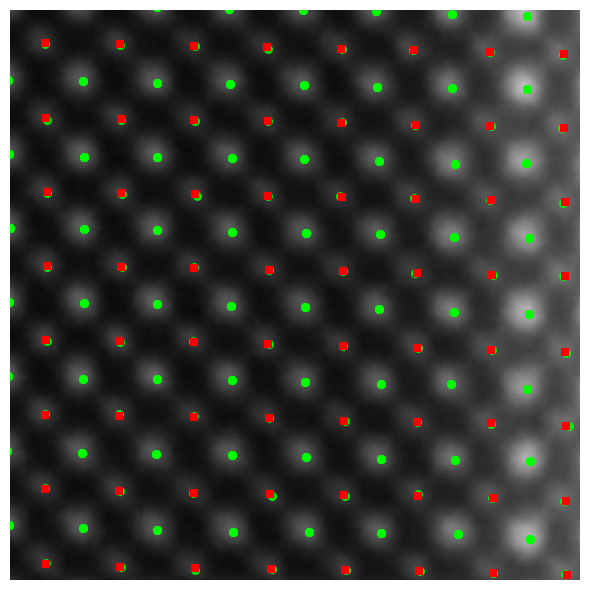

In [7]:
xlim = (500, 700)
ylim = (500, 700)

xy_atms = np.asarray(UCparam[idx]["xy_atms"]).squeeze()

xy = np.asarray(UCparam[idx]["xy_COM"]).T

print("Original shape:", xy_atms.shape)

# Convert coordinates into (N, 2)
if xy_atms.shape[-1] == 2:
    coords = xy_atms.reshape(-1, 2)
elif xy_atms.shape[0] == 2:
    coords = xy_atms.reshape(2, -1).T
else:
    raise ValueError("Inspect xy_atms structure before plotting")

fig, ax = plt.subplots(figsize=(6, 6))

ax.imshow(img, cmap="gray")

ax.scatter(
    coords[:, 1], coords[:, 0],
    s=30, c="lime", alpha=0.8
)

ax.scatter(
    xy[:, 1], xy[:, 0],
    s=30, c="red", marker="s", linewidths=0
)

ax.set_xlim(*xlim)
ax.set_ylim(ylim[1], ylim[0])
ax.set_aspect("equal")
ax.axis("off")

plt.tight_layout()
plt.show()

<font color = "red">**Unit cell**</font>

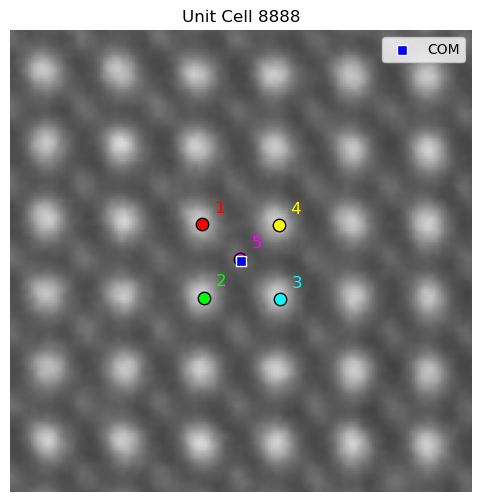

In [8]:
cell = 8888

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")

colors = ["red", "lime", "cyan", "yellow", "magenta"]
atoms = np.asarray(UCparam[idx]["xy_atms"])
com = np.asarray(UCparam[idx]["xy_COM"])

# Plot five atomic positions
for i in range(5):
    y, x = atoms[:, i, cell]
    ax.scatter(x, y, s=80, c=colors[i], edgecolors="black")
    ax.text(x + 4, y - 4, str(i + 1), color=colors[i], fontsize=12)

# Plot center of mass
y_com, x_com = com[:, cell]
ax.scatter(x_com, y_com, s=60, c="blue",
           marker="s", edgecolors="white", label="COM")

# Zoom around the unit cell
x_center = atoms[1, :, cell].mean()
y_center = atoms[0, :, cell].mean()

ax.set_xlim(x_center - 80, x_center + 80)
ax.set_ylim(y_center + 80, y_center - 80)
ax.set_title(f"Unit Cell {cell}")
ax.legend()
ax.set_axis_off()

plt.show()

<font color = "red">**Polarization**</font>

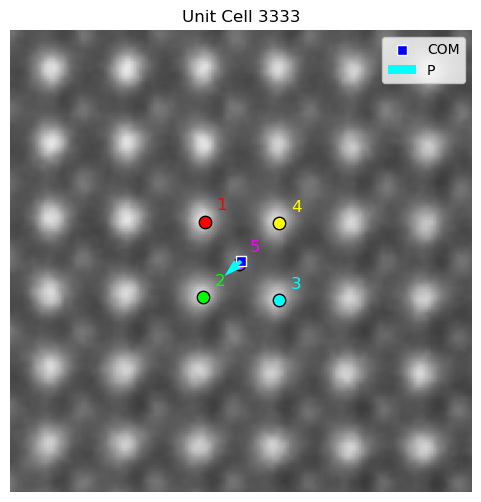

In [9]:
cell = 3333

fig, ax = plt.subplots(figsize=(6, 6))
ax.imshow(img, cmap="gray")

colors = ["red", "lime", "cyan", "yellow", "magenta"]
atoms = np.asarray(UCparam[idx]["xy_atms"])
com = np.asarray(UCparam[idx]["xy_COM"])
pxy = np.asarray(UCparam[idx]["Pxy"])

# Plot five atomic positions
for i in range(5):
    y, x = atoms[:, i, cell]
    ax.scatter(x, y, s=80, c=colors[i], edgecolors="black")
    ax.text(x + 4, y - 4, str(i + 1), color=colors[i], fontsize=12)

# Plot center of mass
y_com, x_com = com[:, cell]
ax.scatter(x_com, y_com, s=60, c="blue",
           marker="s", edgecolors="white", label="COM")

# Plot polarization components
px, py = pxy[:, cell]

scale = 5  # Arrow magnification
ax.quiver(
    x_com, y_com,
    px * scale, py * scale,
    color="cyan",
    angles="xy", scale_units="xy", scale=1,
    width=0.008, label="P"
)

# Zoom
x_center = atoms[1, :, cell].mean()
y_center = atoms[0, :, cell].mean()

ax.set_xlim(x_center - 80, x_center + 80)
ax.set_ylim(y_center + 80, y_center - 80)
ax.set_aspect("equal")
ax.set_title(f"Unit Cell {cell}")
ax.legend()
ax.set_axis_off()

plt.show()

<font color = "tomato">**Challenge Objectives**</font>

The primary task is to reconstruct the two in-plane components of the local polarization proxy, $P_x$ and $P_y$, and generate spatial maps showing their magnitude and direction.

Participants are encouraged to explore different approaches, including:

- Physics-informed analysis: Use atomic positions, local symmetry, and lattice distortions to estimate polarization-related displacements.

- Computer vision and machine learning: Develop methods to identify structural features and predict local properties from microscopy images.

- Advanced or hybrid approaches: Combine physical constraints, statistical modeling, and learned representations to improve the robustness and accuracy of reconstruction.

<font color = "plum">**Important**</font>
* Participants may also investigate additional properties, such as lattice distortion, local strain, structural heterogeneity, or domain boundaries.

<font color = "navy">**Expected Outcomes**</font>

Participants should submit:

- A reproducible Python workflow or Jupyter notebook.

- Reconstructed spatial maps of $P_x$, $P_y$, and polarization-proxy magnitude or orientation.

- Quantitative comparison with the provided reference maps.

- A short explanation of the physical assumptions, methodology, and limitations.

<font color = "magenta">**Central Scientific Question**</font>


Can we develop physics-informed computational methods that reconstruct local polarization-related properties from atomic-resolution microscopy data without relying on precomputed polarization labels?

# Kamyar 

In [137]:
# Crop boundaries
x_min, x_max = 100, 4000
y_min, y_max = 100, 4000

dataset = {}
cropped_dataset = {}

for i in range(len(imgdata)):

    # Load original data
    image = np.asarray(imgdata[i]).squeeze()
    pxy = np.asarray(UCparam[i]["Pxy"]).T
    xy = np.asarray(UCparam[i]["xy_COM"]).T
    volume = np.asarray(UCparam[i]["Vol"]).ravel()

    # Load atomic positions
    xy_atms = np.asarray(UCparam[i]["xy_atms"]).squeeze()

    if xy_atms.shape[-1] == 2:
        atoms = xy_atms.reshape(-1, 2)
    elif xy_atms.shape[0] == 2:
        atoms = xy_atms.reshape(2, -1).T
    else:
        raise ValueError(f"Unexpected xy_atms shape: {xy_atms.shape}")

    # Store original dataset
    dataset[i] = {
        "composition": composition_tags[i],
        "image": image,
        "coordinates": xy,
        "atom_positions": atoms,
        "x": xy[:, 1],
        "y": xy[:, 0],
        "pxy": pxy,
        "px": pxy[:, 0],
        "py": pxy[:, 1],
        "volume": volume,
    }

    # Crop image
    image_crop = image[y_min:y_max, x_min:x_max]

    # Select unit cells
    mask = (
        (x_min <= xy[:, 1]) & (xy[:, 1] < x_max) &
        (y_min <= xy[:, 0]) & (xy[:, 0] < y_max)
    )

    # Select atomic positions
    atom_mask = (
        (x_min <= atoms[:, 1]) & (atoms[:, 1] < x_max) &
        (y_min <= atoms[:, 0]) & (atoms[:, 0] < y_max)
    )

    # Shift coordinates to cropped image
    xy_crop = xy[mask] - [y_min, x_min]
    atoms_crop = atoms[atom_mask] - [y_min, x_min]

    # Store cropped dataset
    cropped_dataset[i] = {
        "composition": composition_tags[i],
        "image": image_crop,
        "coordinates": xy_crop,
        "atom_positions": atoms_crop,
        "x": xy_crop[:, 1],
        "y": xy_crop[:, 0],
        "pxy": pxy[mask],
        "px": pxy[mask, 0],
        "py": pxy[mask, 1],
        "volume": volume[mask],
    }

In [138]:
idx = 2

sample = cropped_dataset[idx]

image = sample["image"]
atoms = sample["atom_positions"]
xy = sample["coordinates"]
px = sample["px"]
py = sample["py"]
volume = sample["volume"]

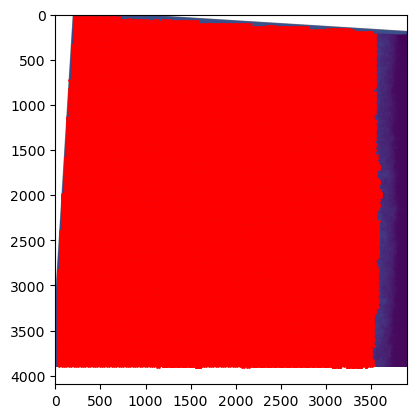

In [139]:
plt.imshow(image)
plt.scatter(atoms[:, 1], atoms[:,0], s = 1, c = "r")

In [141]:
sample = cropped_dataset[idx]

image = sample["image"]
atoms = sample["coordinates"]

# Patch size
patch_size = 21
half = patch_size // 2

patches = []
valid_atoms = []

for y, x in atoms:

    x, y = int(round(x)), int(round(y))

    if (y - half >= 0 and y + half < image.shape[0] and
        x - half >= 0 and x + half < image.shape[1]):

        patch = image[
            y-half:y+half+1,
            x-half:x+half+1
        ]

        patches.append(patch)
        valid_atoms.append([y, x])

patches = np.asarray(patches)
valid_atoms = np.asarray(valid_atoms)

print("Patches:", patches.shape)

Patches: (19293, 21, 21)


In [142]:
# Flatten patches
X = patches.reshape(len(patches), -1).astype(float)

# Standardize features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# PCA
pca = PCA(n_components=min(10, *X_scaled.shape))
X_pca = pca.fit_transform(X_scaled)

# Gaussian Mixture Model
n_clusters = 4

gmm = GaussianMixture(
    n_components=n_clusters,
    covariance_type="full",
    random_state=32,
    n_init=1
)

labels = gmm.fit_predict(X_pca)

print("Cluster populations:", np.bincount(labels))

Cluster populations: [4378 7942 3215 3758]


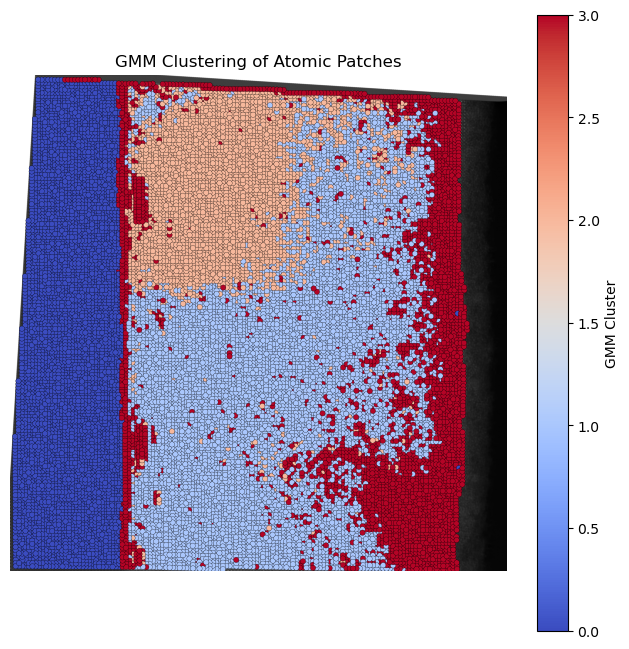

In [144]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.imshow(image, cmap="gray")

scatter = ax.scatter(
    valid_atoms[:, 1],
    valid_atoms[:, 0],
    c=labels,
    cmap="coolwarm",
    s=15,
    edgecolors="black",
    linewidths=0.2
)

ax.set_title("GMM Clustering of Atomic Patches")
ax.axis("off")

plt.colorbar(scatter, ax=ax, label="GMM Cluster")
plt.show()

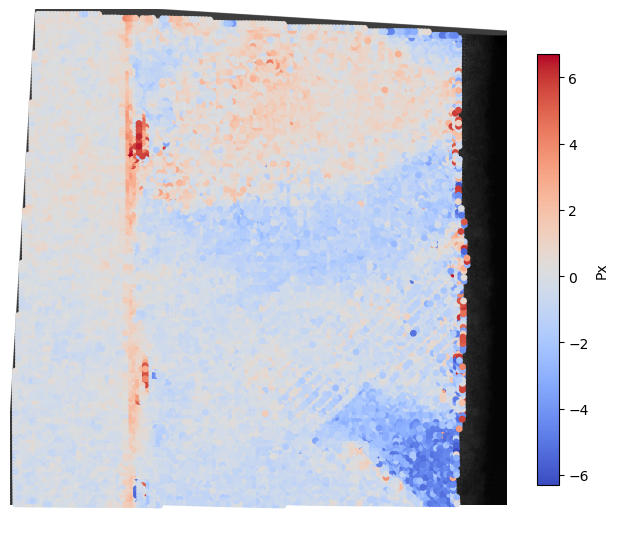

In [145]:
plt.figure(figsize=(8, 8))
plt.imshow(image, cmap="gray")

plt.scatter(
    xy[:, 1], xy[:, 0],
    c=py, cmap="coolwarm", s=15
)

plt.colorbar(label="Px", shrink=0.7)
plt.axis("off")
plt.show()

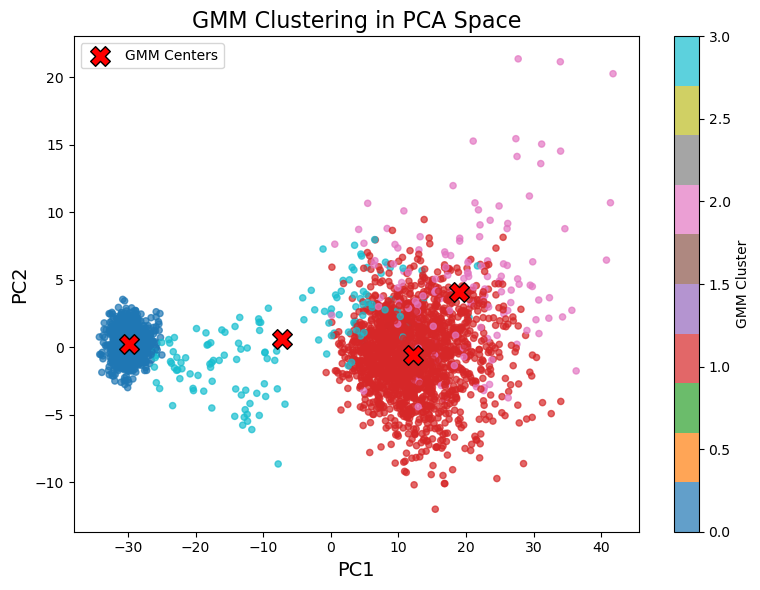

In [117]:
fig, ax = plt.subplots(figsize=(8, 6))

# PCA scatter colored by GMM clusters
scatter = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=labels,
    cmap="tab10",
    s=20,
    alpha=0.7
)

# GMM component centers
ax.scatter(
    gmm.means_[:, 0],
    gmm.means_[:, 1],
    c="red",
    marker="X",
    s=200,
    edgecolors="black",
    label="GMM Centers"
)

ax.set_xlabel("PC1", fontsize=14)
ax.set_ylabel("PC2", fontsize=14)
ax.set_title("GMM Clustering in PCA Space", fontsize=16)

ax.legend()
plt.colorbar(scatter, ax=ax, label="GMM Cluster")
plt.tight_layout()
plt.show()

all

Dataset 0 | Valid patches: 104088 | GMM populations: [ 8060 35657 39657 20714]
Dataset 1 | Valid patches: 102336 | GMM populations: [18480 28760 10725 44371]
Dataset 2 | Valid patches: 96598 | GMM populations: [31658 12659 46755  5526]
Dataset 3 | Valid patches: 84692 | GMM populations: [13530 36135 22715 12312]
Dataset 4 | Valid patches: 103106 | GMM populations: [18636 56344  9603 18523]


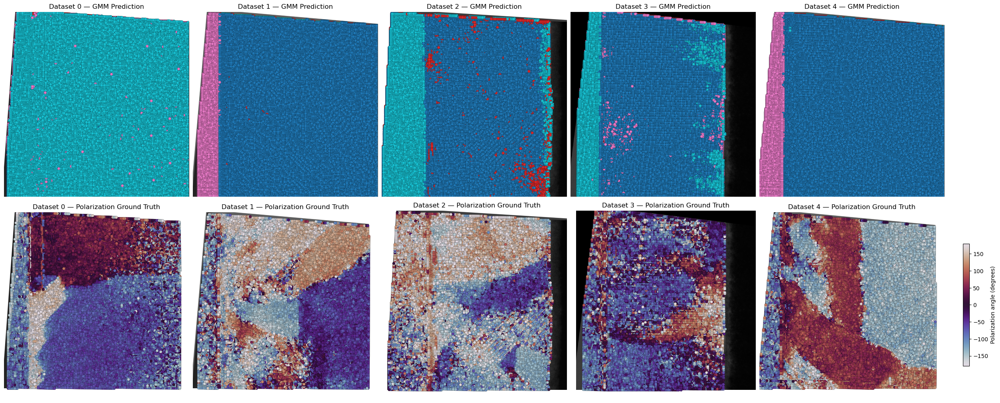

In [150]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture

# ============================================================
# PARAMETERS
# ============================================================

n_clusters = 4
patch_size = 9
n_samples = len(cropped_dataset)

assert patch_size % 2 == 1, "patch_size must be odd"

fig, axes = plt.subplots(
    2, n_samples,
    figsize=(5 * n_samples, 10),
    squeeze=False,
    constrained_layout=True
)

# ============================================================
# LOOP OVER ALL DATASETS
# ============================================================

for idx in range(n_samples):

    sample = cropped_dataset[idx]

    image = np.asarray(sample["image"]).squeeze()
    atoms = np.asarray(sample["atom_positions"])
    coordinates = np.asarray(sample["coordinates"])

    px = np.asarray(sample["px"]).ravel()
    py = np.asarray(sample["py"]).ravel()

    # ========================================================
    # EXTRACT ATOMIC PATCHES (REMOVE NaN / INF)
    # ========================================================

    patches = []
    valid_atoms = []

    half = patch_size // 2

    for y, x in atoms:

        # Skip invalid atomic coordinates
        if not np.isfinite(y) or not np.isfinite(x):
            continue

        y = int(round(y))
        x = int(round(x))

        # Skip patches outside image boundaries
        if (
            y - half < 0 or
            x - half < 0 or
            y + half >= image.shape[0] or
            x + half >= image.shape[1]
        ):
            continue

        patch = image[
            y-half:y+half+1,
            x-half:x+half+1
        ]

        # Keep only finite patches
        if (
            patch.shape == (patch_size, patch_size)
            and np.isfinite(patch).all()
        ):
            patches.append(patch)
            valid_atoms.append([y, x])

    patches = np.asarray(patches)
    valid_atoms = np.asarray(valid_atoms)

    if len(patches) < n_clusters:
        print(f"Dataset {idx}: insufficient valid patches")
        for ax in axes[:, idx]:
            ax.axis("off")
        continue

    # ========================================================
    # FLATTEN PATCHES
    # ========================================================

    X = patches.reshape(len(patches), -1).astype(float)

    # ========================================================
    # STANDARDIZATION
    # ========================================================

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)

    # Additional safety check
    finite_mask = np.isfinite(X_scaled).all(axis=1)

    X_scaled = X_scaled[finite_mask]
    valid_atoms = valid_atoms[finite_mask]

    if len(X_scaled) < n_clusters:
        print(f"Dataset {idx}: insufficient finite samples")
        for ax in axes[:, idx]:
            ax.axis("off")
        continue

    # ========================================================
    # PCA
    # ========================================================

    n_components = min(
        10,
        X_scaled.shape[0],
        X_scaled.shape[1]
    )

    pca = PCA(
        n_components=n_components,
        random_state=32
    )

    X_pca = pca.fit_transform(X_scaled)

    # ========================================================
    # GAUSSIAN MIXTURE MODEL
    # ========================================================

    gmm = GaussianMixture(
        n_components=n_clusters,
        covariance_type="full",
        random_state=32,
        n_init=1,
        reg_covar=1e-6
    )

    labels = gmm.fit_predict(X_pca)

    print(
        f"Dataset {idx} | "
        f"Valid patches: {len(X_scaled)} | "
        f"GMM populations: "
        f"{np.bincount(labels, minlength=n_clusters)}"
    )

    # ========================================================
    # POLARIZATION GROUND TRUTH
    # ========================================================

    # Polarization direction in degrees
    polarization_angle = np.degrees(
        np.arctan2(py, px)
    )

    # Assumes coordinates is (N, 2) in (y, x) pixel order
    gt_coords = coordinates.reshape(-1, 2)

    if len(gt_coords) != len(polarization_angle):
        print(
            f"Dataset {idx}: polarization coordinate mismatch "
            f"({len(gt_coords)} coordinates vs "
            f"{len(polarization_angle)} values)"
        )
        gt_available = False
    else:
        gt_available = True

        gt_mask = (
            np.isfinite(gt_coords).all(axis=1)
            & np.isfinite(px)
            & np.isfinite(py)
            & ((px != 0) | (py != 0))
        )

        gt_coords = gt_coords[gt_mask]
        polarization_angle = polarization_angle[gt_mask]

    # ========================================================
    # ROW 1: GMM PREDICTIONS
    # ========================================================

    ax = axes[0, idx]

    ax.imshow(image, cmap="gray")

    ax.scatter(
        valid_atoms[:, 1],
        valid_atoms[:, 0],
        c=labels,
        cmap="tab10",
        vmin=0,
        vmax=n_clusters - 1,
        s=25,
        edgecolors="black",
        linewidths=0.2
    )

    ax.set_title(f"Dataset {idx} — GMM Prediction")
    ax.axis("off")

    # ========================================================
    # ROW 2: POLARIZATION GROUND TRUTH
    # ========================================================

    ax = axes[1, idx]

    ax.imshow(image, cmap="gray")

    if gt_available:

        sc = ax.scatter(
            gt_coords[:, 1],
            gt_coords[:, 0],
            c=polarization_angle,
            cmap="twilight",
            vmin=-180,
            vmax=180,
            s=25,
            edgecolors="black",
            linewidths=0.2
        )

    else:
        ax.text(
            0.5, 0.5,
            "Polarization coordinates unavailable",
            transform=ax.transAxes,
            ha="center",
            va="center",
            color="red"
        )

    ax.set_title(f"Dataset {idx} — Polarization Ground Truth")
    ax.axis("off")

# ============================================================
# POLARIZATION COLORBAR
# ============================================================

sm = plt.cm.ScalarMappable(
    cmap="twilight",
    norm=plt.Normalize(vmin=-180, vmax=180)
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes[1, :].tolist(),
    shrink=0.65,
    pad=0.02
)

cbar.set_label("Polarization angle (degrees)")

plt.show()

Dataset 0 | Valid atoms: 104088 | Cluster populations: [37751 28474  2103 35760]
Dataset 1 | Valid atoms: 102336 | Cluster populations: [36040 28755 31658  5883]
Dataset 2 | Valid atoms: 96598 | Cluster populations: [37369 33888 23993  1348]
Dataset 3 | Valid atoms: 84692 | Cluster populations: [ 8458 30125  1567 44542]
Dataset 4 | Valid atoms: 103106 | Cluster populations: [15375 35138 20246 32347]


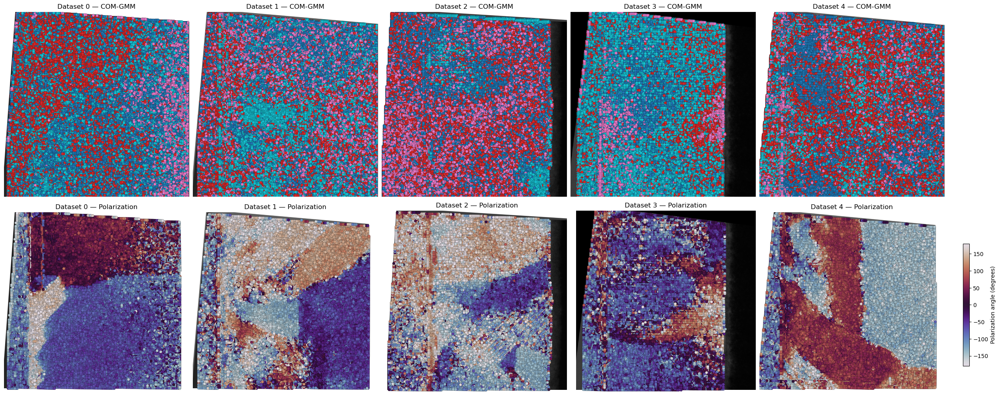

In [151]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from matplotlib.colors import Normalize

# ============================================================
# PARAMETERS
# ============================================================

n_clusters = 4
patch_size = 9
n_samples = len(cropped_dataset)

assert patch_size % 2 == 1, "patch_size must be odd"

fig, axes = plt.subplots(
    2, n_samples,
    figsize=(5 * n_samples, 10),
    squeeze=False,
    constrained_layout=True
)

com_results = {}

# ============================================================
# LOOP OVER ALL DATASET INDICES
# ============================================================

for idx in range(n_samples):

    sample = cropped_dataset[idx]

    image = np.asarray(sample["image"], dtype=float).squeeze()
    atoms = np.asarray(sample["atom_positions"])

    coordinates = np.asarray(sample["coordinates"])
    px = np.asarray(sample["px"]).ravel()
    py = np.asarray(sample["py"]).ravel()

    # ========================================================
    # EXTRACT PATCHES AND CALCULATE CENTER OF MASS
    # ========================================================

    half = patch_size // 2

    yy, xx = np.indices((patch_size, patch_size))

    com_features = []
    valid_atoms = []

    for y, x in atoms:

        if not np.isfinite(y) or not np.isfinite(x):
            continue

        y = int(round(y))
        x = int(round(x))

        # Check image boundaries
        if (
            y - half < 0 or
            x - half < 0 or
            y + half >= image.shape[0] or
            x + half >= image.shape[1]
        ):
            continue

        patch = image[
            y-half:y+half+1,
            x-half:x+half+1
        ]

        # Remove NaN / Inf patches
        if (
            patch.shape != (patch_size, patch_size)
            or not np.isfinite(patch).all()
        ):
            continue

        # Nonnegative intensity weights
        weights = patch - patch.min()

        total_intensity = weights.sum()

        if total_intensity <= 0:
            continue

        # Intensity-weighted COM
        x_com = np.sum(xx * weights) / total_intensity
        y_com = np.sum(yy * weights) / total_intensity

        # COM displacement relative to patch center
        dx_com = x_com - half
        dy_com = y_com - half

        com_features.append([dx_com, dy_com])
        valid_atoms.append([y, x])

    com_features = np.asarray(com_features)
    valid_atoms = np.asarray(valid_atoms)

    if len(com_features) < n_clusters:
        print(f"Dataset {idx}: insufficient valid patches")

        for ax in axes[:, idx]:
            ax.axis("off")

        continue

    # ========================================================
    # STANDARDIZE COM FEATURES
    # ========================================================

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(com_features)

    # ========================================================
    # GMM ON COM DISPLACEMENTS
    # ========================================================

    gmm = GaussianMixture(
        n_components=n_clusters,
        covariance_type="full",
        random_state=32,
        n_init=5,
        reg_covar=1e-6
    )

    labels = gmm.fit_predict(X_scaled)

    com_results[idx] = {
        "positions": valid_atoms,
        "com_features": com_features,
        "labels": labels,
        "gmm": gmm,
        "scaler": scaler
    }

    print(
        f"Dataset {idx} | "
        f"Valid atoms: {len(valid_atoms)} | "
        f"Cluster populations: "
        f"{np.bincount(labels, minlength=n_clusters)}"
    )

    # ========================================================
    # GROUND-TRUTH POLARIZATION
    # ========================================================

    polarization_angle = np.degrees(
        np.arctan2(py, px)
    )

    gt_coords = coordinates.reshape(-1, 2)

    gt_available = len(gt_coords) == len(px) == len(py)

    if gt_available:

        gt_mask = (
            np.isfinite(gt_coords).all(axis=1)
            & np.isfinite(px)
            & np.isfinite(py)
            & ((px != 0) | (py != 0))
        )

        gt_coords = gt_coords[gt_mask]
        polarization_angle = polarization_angle[gt_mask]

    else:
        print(f"Dataset {idx}: polarization coordinate mismatch")

    # ========================================================
    # ROW 1: GMM PREDICTION USING COM
    # ========================================================

    ax = axes[0, idx]

    ax.imshow(image, cmap="gray")

    ax.scatter(
        valid_atoms[:, 1],
        valid_atoms[:, 0],
        c=labels,
        cmap="tab10",
        vmin=0,
        vmax=n_clusters - 1,
        s=25,
        edgecolors="black",
        linewidths=0.2
    )

    ax.set_title(f"Dataset {idx} — COM-GMM")
    ax.axis("off")

    # ========================================================
    # ROW 2: POLARIZATION GROUND TRUTH
    # ========================================================

    ax = axes[1, idx]

    ax.imshow(image, cmap="gray")

    if gt_available:

        ax.scatter(
            gt_coords[:, 1],
            gt_coords[:, 0],
            c=polarization_angle,
            cmap="twilight",
            vmin=-180,
            vmax=180,
            s=25,
            edgecolors="black",
            linewidths=0.2
        )

    else:
        ax.text(
            0.5, 0.5,
            "Polarization unavailable",
            transform=ax.transAxes,
            ha="center",
            va="center"
        )

    ax.set_title(f"Dataset {idx} — Polarization")
    ax.axis("off")

# ============================================================
# COLORBAR FOR POLARIZATION
# ============================================================

sm = plt.cm.ScalarMappable(
    norm=Normalize(vmin=-180, vmax=180),
    cmap="twilight"
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes[1, :].tolist(),
    shrink=0.65,
    pad=0.02
)

cbar.set_label("Polarization angle (degrees)")

plt.show()

Dataset 0 | Valid atoms: 103947 | Cluster populations: [43525  3137 43514 13771]
Dataset 1 | Valid atoms: 102208 | Cluster populations: [11107 40439  7286 43376]
Dataset 2 | Valid atoms: 96517 | Cluster populations: [40295  5132 40211 10879]
Dataset 3 | Valid atoms: 84672 | Cluster populations: [ 3193 34045 35109 12325]
Dataset 4 | Valid atoms: 102918 | Cluster populations: [ 7717 43726 41735  9740]


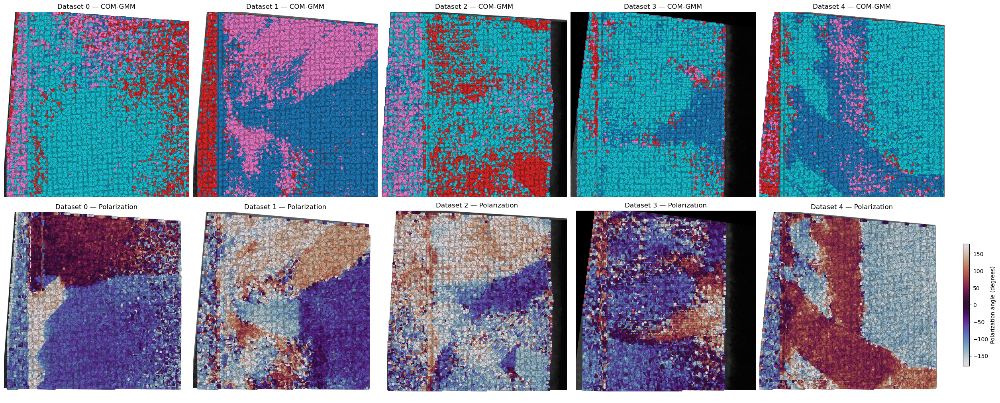

In [153]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from matplotlib.colors import Normalize

# ============================================================
# PARAMETERS
# ============================================================

n_clusters = 4
patch_size = 15
n_samples = len(cropped_dataset)

assert patch_size % 2 == 1, "patch_size must be odd"

fig, axes = plt.subplots(
    2, n_samples,
    figsize=(5 * n_samples, 10),
    squeeze=False,
    constrained_layout=True
)

com_results = {}

# ============================================================
# LOOP OVER ALL DATASET INDICES
# ============================================================

for idx in range(n_samples):

    sample = cropped_dataset[idx]

    image = np.asarray(sample["image"], dtype=float).squeeze()
    atoms = np.asarray(sample["atom_positions"])

    coordinates = np.asarray(sample["coordinates"])
    px = np.asarray(sample["px"]).ravel()
    py = np.asarray(sample["py"]).ravel()

    # ========================================================
    # EXTRACT PATCHES AND CALCULATE CENTER OF MASS
    # ========================================================

    half = patch_size // 2

    yy, xx = np.indices((patch_size, patch_size))

    com_features = []
    valid_atoms = []

    for y, x in atoms:

        if not np.isfinite(y) or not np.isfinite(x):
            continue

        y = int(round(y))
        x = int(round(x))

        # Check image boundaries
        if (
            y - half < 0 or
            x - half < 0 or
            y + half >= image.shape[0] or
            x + half >= image.shape[1]
        ):
            continue

        patch = image[
            y-half:y+half+1,
            x-half:x+half+1
        ]

        # Remove NaN / Inf patches
        if (
            patch.shape != (patch_size, patch_size)
            or not np.isfinite(patch).all()
        ):
            continue

        # Nonnegative intensity weights
        weights = patch - patch.min()

        total_intensity = weights.sum()

        if total_intensity <= 0:
            continue

        # Intensity-weighted COM
        x_com = np.sum(xx * weights) / total_intensity
        y_com = np.sum(yy * weights) / total_intensity

        # COM displacement relative to patch center
        dx_com = x_com - half
        dy_com = y_com - half

        com_features.append([dx_com, dy_com])
        valid_atoms.append([y, x])

    com_features = np.asarray(com_features)
    valid_atoms = np.asarray(valid_atoms)

    if len(com_features) < n_clusters:
        print(f"Dataset {idx}: insufficient valid patches")

        for ax in axes[:, idx]:
            ax.axis("off")

        continue

    # ========================================================
    # STANDARDIZE COM FEATURES
    # ========================================================

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(com_features)

    # ========================================================
    # GMM ON COM DISPLACEMENTS
    # ========================================================

    gmm = GaussianMixture(
        n_components=n_clusters,
        covariance_type="full",
        random_state=32,
        n_init=5,
        reg_covar=1e-6
    )

    labels = gmm.fit_predict(X_scaled)

    com_results[idx] = {
        "positions": valid_atoms,
        "com_features": com_features,
        "labels": labels,
        "gmm": gmm,
        "scaler": scaler
    }

    print(
        f"Dataset {idx} | "
        f"Valid atoms: {len(valid_atoms)} | "
        f"Cluster populations: "
        f"{np.bincount(labels, minlength=n_clusters)}"
    )

    # ========================================================
    # GROUND-TRUTH POLARIZATION
    # ========================================================

    polarization_angle = np.degrees(
        np.arctan2(py, px)
    )

    gt_coords = coordinates.reshape(-1, 2)

    gt_available = len(gt_coords) == len(px) == len(py)

    if gt_available:

        gt_mask = (
            np.isfinite(gt_coords).all(axis=1)
            & np.isfinite(px)
            & np.isfinite(py)
            & ((px != 0) | (py != 0))
        )

        gt_coords = gt_coords[gt_mask]
        polarization_angle = polarization_angle[gt_mask]

    else:
        print(f"Dataset {idx}: polarization coordinate mismatch")

    # ========================================================
    # ROW 1: GMM PREDICTION USING COM
    # ========================================================

    ax = axes[0, idx]

    ax.imshow(image, cmap="gray")

    ax.scatter(
        valid_atoms[:, 1],
        valid_atoms[:, 0],
        c=labels,
        cmap="tab10",
        vmin=0,
        vmax=n_clusters - 1,
        s=25,
        edgecolors="black",
        linewidths=0.2
    )

    ax.set_title(f"Dataset {idx} — COM-GMM")
    ax.axis("off")

    # ========================================================
    # ROW 2: POLARIZATION GROUND TRUTH
    # ========================================================

    ax = axes[1, idx]

    ax.imshow(image, cmap="gray")

    if gt_available:

        ax.scatter(
            gt_coords[:, 1],
            gt_coords[:, 0],
            c=polarization_angle,
            cmap="twilight",
            vmin=-180,
            vmax=180,
            s=25,
            edgecolors="black",
            linewidths=0.2
        )

    else:
        ax.text(
            0.5, 0.5,
            "Polarization unavailable",
            transform=ax.transAxes,
            ha="center",
            va="center"
        )

    ax.set_title(f"Dataset {idx} — Polarization")
    ax.axis("off")

# ============================================================
# COLORBAR FOR POLARIZATION
# ============================================================

sm = plt.cm.ScalarMappable(
    norm=Normalize(vmin=-180, vmax=180),
    cmap="twilight"
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes[1, :].tolist(),
    shrink=0.65,
    pad=0.02
)

cbar.set_label("Polarization angle (degrees)")

plt.show()

Dataset 0 | Valid atoms: 103898 | Cluster populations: [40517  5275 43667 14439]
Dataset 1 | Valid atoms: 102179 | Cluster populations: [36823 11190 46365  7801]
Dataset 2 | Valid atoms: 96489 | Cluster populations: [40646  7744 11226 36873]
Dataset 3 | Valid atoms: 84650 | Cluster populations: [33457  3414 34856 12923]
Dataset 4 | Valid atoms: 102851 | Cluster populations: [40390  8152 11004 43305]


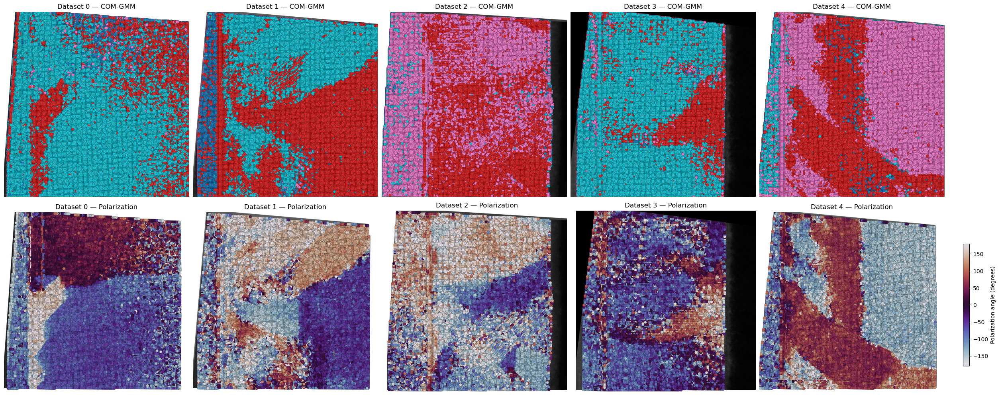

In [154]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from matplotlib.colors import Normalize

# ============================================================
# PARAMETERS
# ============================================================

n_clusters = 4
patch_size = 17
n_samples = len(cropped_dataset)

assert patch_size % 2 == 1, "patch_size must be odd"

fig, axes = plt.subplots(
    2, n_samples,
    figsize=(5 * n_samples, 10),
    squeeze=False,
    constrained_layout=True
)

com_results = {}

# ============================================================
# LOOP OVER ALL DATASET INDICES
# ============================================================

for idx in range(n_samples):

    sample = cropped_dataset[idx]

    image = np.asarray(sample["image"], dtype=float).squeeze()
    atoms = np.asarray(sample["atom_positions"])

    coordinates = np.asarray(sample["coordinates"])
    px = np.asarray(sample["px"]).ravel()
    py = np.asarray(sample["py"]).ravel()

    # ========================================================
    # EXTRACT PATCHES AND CALCULATE CENTER OF MASS
    # ========================================================

    half = patch_size // 2

    yy, xx = np.indices((patch_size, patch_size))

    com_features = []
    valid_atoms = []

    for y, x in atoms:

        if not np.isfinite(y) or not np.isfinite(x):
            continue

        y = int(round(y))
        x = int(round(x))

        # Check image boundaries
        if (
            y - half < 0 or
            x - half < 0 or
            y + half >= image.shape[0] or
            x + half >= image.shape[1]
        ):
            continue

        patch = image[
            y-half:y+half+1,
            x-half:x+half+1
        ]

        # Remove NaN / Inf patches
        if (
            patch.shape != (patch_size, patch_size)
            or not np.isfinite(patch).all()
        ):
            continue

        # Nonnegative intensity weights
        weights = patch - patch.min()

        total_intensity = weights.sum()

        if total_intensity <= 0:
            continue

        # Intensity-weighted COM
        x_com = np.sum(xx * weights) / total_intensity
        y_com = np.sum(yy * weights) / total_intensity

        # COM displacement relative to patch center
        dx_com = x_com - half
        dy_com = y_com - half

        com_features.append([dx_com, dy_com])
        valid_atoms.append([y, x])

    com_features = np.asarray(com_features)
    valid_atoms = np.asarray(valid_atoms)

    if len(com_features) < n_clusters:
        print(f"Dataset {idx}: insufficient valid patches")

        for ax in axes[:, idx]:
            ax.axis("off")

        continue

    # ========================================================
    # STANDARDIZE COM FEATURES
    # ========================================================

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(com_features)

    # ========================================================
    # GMM ON COM DISPLACEMENTS
    # ========================================================

    gmm = GaussianMixture(
        n_components=n_clusters,
        covariance_type="full",
        random_state=32,
        n_init=5,
        reg_covar=1e-6
    )

    labels = gmm.fit_predict(X_scaled)

    com_results[idx] = {
        "positions": valid_atoms,
        "com_features": com_features,
        "labels": labels,
        "gmm": gmm,
        "scaler": scaler
    }

    print(
        f"Dataset {idx} | "
        f"Valid atoms: {len(valid_atoms)} | "
        f"Cluster populations: "
        f"{np.bincount(labels, minlength=n_clusters)}"
    )

    # ========================================================
    # GROUND-TRUTH POLARIZATION
    # ========================================================

    polarization_angle = np.degrees(
        np.arctan2(py, px)
    )

    gt_coords = coordinates.reshape(-1, 2)

    gt_available = len(gt_coords) == len(px) == len(py)

    if gt_available:

        gt_mask = (
            np.isfinite(gt_coords).all(axis=1)
            & np.isfinite(px)
            & np.isfinite(py)
            & ((px != 0) | (py != 0))
        )

        gt_coords = gt_coords[gt_mask]
        polarization_angle = polarization_angle[gt_mask]

    else:
        print(f"Dataset {idx}: polarization coordinate mismatch")

    # ========================================================
    # ROW 1: GMM PREDICTION USING COM
    # ========================================================

    ax = axes[0, idx]

    ax.imshow(image, cmap="gray")

    ax.scatter(
        valid_atoms[:, 1],
        valid_atoms[:, 0],
        c=labels,
        cmap="tab10",
        vmin=0,
        vmax=n_clusters - 1,
        s=25,
        edgecolors="black",
        linewidths=0.2
    )

    ax.set_title(f"Dataset {idx} — COM-GMM")
    ax.axis("off")

    # ========================================================
    # ROW 2: POLARIZATION GROUND TRUTH
    # ========================================================

    ax = axes[1, idx]

    ax.imshow(image, cmap="gray")

    if gt_available:

        ax.scatter(
            gt_coords[:, 1],
            gt_coords[:, 0],
            c=polarization_angle,
            cmap="twilight",
            vmin=-180,
            vmax=180,
            s=25,
            edgecolors="black",
            linewidths=0.2
        )

    else:
        ax.text(
            0.5, 0.5,
            "Polarization unavailable",
            transform=ax.transAxes,
            ha="center",
            va="center"
        )

    ax.set_title(f"Dataset {idx} — Polarization")
    ax.axis("off")

# ============================================================
# COLORBAR FOR POLARIZATION
# ============================================================

sm = plt.cm.ScalarMappable(
    norm=Normalize(vmin=-180, vmax=180),
    cmap="twilight"
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes[1, :].tolist(),
    shrink=0.65,
    pad=0.02
)

cbar.set_label("Polarization angle (degrees)")

plt.show()

Dataset 0 | Valid atoms: 103808 | Cluster populations: [10511 40159 43666  9472]
Dataset 1 | Valid atoms: 102116 | Cluster populations: [ 7913 80787  6172  7244]
Dataset 2 | Valid atoms: 96427 | Cluster populations: [ 6032 76882  7788  5725]
Dataset 3 | Valid atoms: 84589 | Cluster populations: [37583 13705  3405 29896]
Dataset 4 | Valid atoms: 102668 | Cluster populations: [ 4612 82417  7361  8278]


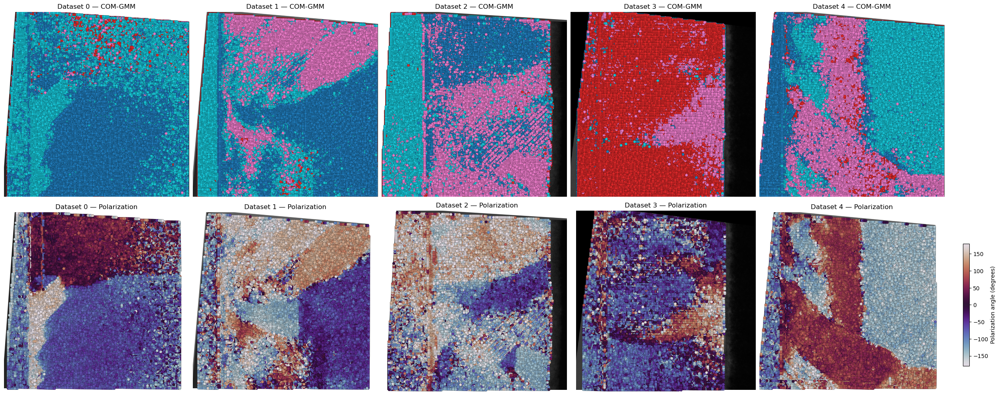

In [155]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
from matplotlib.colors import Normalize

# ============================================================
# PARAMETERS
# ============================================================

n_clusters = 4
patch_size = 21
n_samples = len(cropped_dataset)

assert patch_size % 2 == 1, "patch_size must be odd"

fig, axes = plt.subplots(
    2, n_samples,
    figsize=(5 * n_samples, 10),
    squeeze=False,
    constrained_layout=True
)

com_results = {}

# ============================================================
# LOOP OVER ALL DATASET INDICES
# ============================================================

for idx in range(n_samples):

    sample = cropped_dataset[idx]

    image = np.asarray(sample["image"], dtype=float).squeeze()
    atoms = np.asarray(sample["atom_positions"])

    coordinates = np.asarray(sample["coordinates"])
    px = np.asarray(sample["px"]).ravel()
    py = np.asarray(sample["py"]).ravel()

    # ========================================================
    # EXTRACT PATCHES AND CALCULATE CENTER OF MASS
    # ========================================================

    half = patch_size // 2

    yy, xx = np.indices((patch_size, patch_size))

    com_features = []
    valid_atoms = []

    for y, x in atoms:

        if not np.isfinite(y) or not np.isfinite(x):
            continue

        y = int(round(y))
        x = int(round(x))

        # Check image boundaries
        if (
            y - half < 0 or
            x - half < 0 or
            y + half >= image.shape[0] or
            x + half >= image.shape[1]
        ):
            continue

        patch = image[
            y-half:y+half+1,
            x-half:x+half+1
        ]

        # Remove NaN / Inf patches
        if (
            patch.shape != (patch_size, patch_size)
            or not np.isfinite(patch).all()
        ):
            continue

        # Nonnegative intensity weights
        weights = patch - patch.min()

        total_intensity = weights.sum()

        if total_intensity <= 0:
            continue

        # Intensity-weighted COM
        x_com = np.sum(xx * weights) / total_intensity
        y_com = np.sum(yy * weights) / total_intensity

        # COM displacement relative to patch center
        dx_com = x_com - half
        dy_com = y_com - half

        com_features.append([dx_com, dy_com])
        valid_atoms.append([y, x])

    com_features = np.asarray(com_features)
    valid_atoms = np.asarray(valid_atoms)

    if len(com_features) < n_clusters:
        print(f"Dataset {idx}: insufficient valid patches")

        for ax in axes[:, idx]:
            ax.axis("off")

        continue

    # ========================================================
    # STANDARDIZE COM FEATURES
    # ========================================================

    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(com_features)

    # ========================================================
    # GMM ON COM DISPLACEMENTS
    # ========================================================

    gmm = GaussianMixture(
        n_components=n_clusters,
        covariance_type="full",
        random_state=32,
        n_init=5,
        reg_covar=1e-6
    )

    labels = gmm.fit_predict(X_scaled)

    com_results[idx] = {
        "positions": valid_atoms,
        "com_features": com_features,
        "labels": labels,
        "gmm": gmm,
        "scaler": scaler
    }

    print(
        f"Dataset {idx} | "
        f"Valid atoms: {len(valid_atoms)} | "
        f"Cluster populations: "
        f"{np.bincount(labels, minlength=n_clusters)}"
    )

    # ========================================================
    # GROUND-TRUTH POLARIZATION
    # ========================================================

    polarization_angle = np.degrees(
        np.arctan2(py, px)
    )

    gt_coords = coordinates.reshape(-1, 2)

    gt_available = len(gt_coords) == len(px) == len(py)

    if gt_available:

        gt_mask = (
            np.isfinite(gt_coords).all(axis=1)
            & np.isfinite(px)
            & np.isfinite(py)
            & ((px != 0) | (py != 0))
        )

        gt_coords = gt_coords[gt_mask]
        polarization_angle = polarization_angle[gt_mask]

    else:
        print(f"Dataset {idx}: polarization coordinate mismatch")

    # ========================================================
    # ROW 1: GMM PREDICTION USING COM
    # ========================================================

    ax = axes[0, idx]

    ax.imshow(image, cmap="gray")

    ax.scatter(
        valid_atoms[:, 1],
        valid_atoms[:, 0],
        c=labels,
        cmap="tab10",
        vmin=0,
        vmax=n_clusters - 1,
        s=25,
        edgecolors="black",
        linewidths=0.2
    )

    ax.set_title(f"Dataset {idx} — COM-GMM")
    ax.axis("off")

    # ========================================================
    # ROW 2: POLARIZATION GROUND TRUTH
    # ========================================================

    ax = axes[1, idx]

    ax.imshow(image, cmap="gray")

    if gt_available:

        ax.scatter(
            gt_coords[:, 1],
            gt_coords[:, 0],
            c=polarization_angle,
            cmap="twilight",
            vmin=-180,
            vmax=180,
            s=25,
            edgecolors="black",
            linewidths=0.2
        )

    else:
        ax.text(
            0.5, 0.5,
            "Polarization unavailable",
            transform=ax.transAxes,
            ha="center",
            va="center"
        )

    ax.set_title(f"Dataset {idx} — Polarization")
    ax.axis("off")

# ============================================================
# COLORBAR FOR POLARIZATION
# ============================================================

sm = plt.cm.ScalarMappable(
    norm=Normalize(vmin=-180, vmax=180),
    cmap="twilight"
)

sm.set_array([])

cbar = fig.colorbar(
    sm,
    ax=axes[1, :].tolist(),
    shrink=0.65,
    pad=0.02
)

cbar.set_label("Polarization angle (degrees)")

plt.show()